##### Master Degree in Computer Science and Data Science for Economics and Health

# Reading a sequence: recurrent networks and positional embeddings

### Prof. Alfio Ferrara

## Introduction

The previous notebook ended with a neural language model that reads a **window** of the $k$ words before the one to be predicted. In this notebook we ask what happens when the information that we need is farther than the window, and we follow the answer step by step, all on **one toy dataset that we can control**:

1. a network like that of Bengio et al. (2003) gets into trouble because of its **window**: what is farther than $k$ words is invisible to it;
2. a **recurrent network** (RNN) solves the problem: it reads a sequence of any length, with the same weights at each step, and keeps in a vector a summary of what it has read;
3. but recurrent networks have problems of their own: they process the words **one after the other**, which is slow, and the **signal of a distant word fades** along the way, so that the network can not learn from it;
4. **LSTM** and **GRU** are the classical fix for the second problem (theory only);
5. even with this fix, a recurrent network does not **discriminate which words are really relevant** for a prediction: we ask a question at the end of a list and the network must keep the whole list;
6. a different way of handling the order of the words: instead of delegating it to the process of reading, we make it **explicit** in the embedding, with the **positional embeddings**. This gives us a sequence that can be processed at once, and it leaves open how to **use** this information, which is the subject of the next notebook.

We use toy datasets and no real corpus. The reason is that in the toy we know exactly what the model needs to learn and how far it is, and we can change the difficulty.

## The toy dataset: who drinks what, and how far away the person is

We invent a tiny world with **one fact to learn**: what each person drinks. There are four people and four drinks, and each person always drinks the same drink:

| person | `anna` | `marco` | `luca` | `sara` |
|---|---|---|---|---|
| drink | `coffee` | `tea` | `milk` | `juice` |

A sentence says it in the simplest form, `anna drinks coffee`. A model that reads `anna drinks` and predicts `coffee` has understood the fact. What we control is the **construction of the examples**: between the person and the verb we insert $L$ **filler words**, drawn at random among eight (`the`, `kitchen`, `today`, `and`, `slowly`, `then`, `also`, `always`), and we get sentences such as `anna the kitchen today drinks coffee`. The fillers are random and carry no information, so the only way to predict the drink is to **remember the person** across the fillers. $L$ is the distance between the information that we need (the person) and the place where we need it (the drink, $L + 2$ words after the person). The fact to learn is the same for every $L$; what changes is **how far away** the information is.

We train on sentences with $L$ from 0 to 8 and we test on $L$ from 0 to 40, much longer than any sentence seen in training. As in the previous notebooks all the models are trained as language models, that is to predict **every** word of the sentences (most of them fillers, which can not be predicted), but we measure a **single prediction: the drink, after `drinks`**. For each $L$ we take the probability $P$ that the model gives to the right drink and we report the **loss** $-\log P$ (in nats) and the **accuracy** (how often the most probable drink is the right one). The loss is 0 if the model is sure of the right drink, 0.69 if it gives it probability one half, $\log 4 = 1.39$ if it chooses among the four drinks at random, and 13.8 if it gives the right drink one chance in a million. The perplexity of the previous notebooks is the exponential of the loss: 1 for a model that is sure, 4 for the random choice among four drinks.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from nlp import lm

people = ["anna", "marco", "luca", "sara"]
drinks = ["coffee", "tea", "milk", "juice"]
fillers = ["the", "kitchen", "today", "and", "slowly", "then", "also", "always"]
words = ["<unk>", "<s>", "</s>", "drinks"] + people + fillers + drinks
index_of = {w: i for i, w in enumerate(words)}
V = len(words)
START, END = index_of["<s>"], index_of["</s>"]

def sentences(rng, L, n):
    # n sentences with L fillers, as arrays of word indices: <s> person fillers drinks drink </s>
    person = rng.integers(len(people), size=n)
    out = np.empty((n, L + 5), dtype=np.int64)
    out[:, 0] = START
    out[:, 1] = index_of["anna"] + person                             # people, fillers and drinks are consecutive in the vocabulary
    out[:, 2:L + 2] = index_of["the"] + rng.integers(len(fillers), size=(n, L))
    out[:, L + 2] = index_of["drinks"]
    out[:, L + 3] = index_of["coffee"] + person                       # the drink is determined by the person
    out[:, L + 4] = END
    return out

show = lambda s: " ".join(words[i] for i in s[1:-1])
rng = np.random.default_rng(3)
for L in (0, 4, 8):
    print(f"L = {L}:", show(sentences(rng, L, 1)[0]))

rng = np.random.default_rng(0)
train_by_L = {L: sentences(rng, L, 1000) for L in range(9)}                         # 9,000 sentences, L from 0 to 8
test_by_L = {L: sentences(np.random.default_rng(100 + L), L, 400) for L in range(41)}  # 400 sentences for each L from 0 to 40

L = 0: sara drinks juice
L = 4: anna kitchen kitchen kitchen also drinks coffee
L = 8: sara slowly the the today and slowly and today drinks juice


## Step 1: a window network has a wall

The first model is the one of the previous notebook (Bengio et al., 2003), that we call the **window network**. To predict a word it reads only the $k$ words that precede it (a window on the left, padded with `<s>` at the beginning of a sentence), it replaces each of them with its embedding (the same table of embeddings for all the positions of the window), it concatenates the $k$ vectors, it passes them through a layer of neurons with ReLU, and it computes the probabilities of the words with a softmax. Here the embeddings have size 8 and the layer has 32 neurons. We train two windows, with $k = 4$ and $k = 10$, on the 9,000 sentences.

The person is $L + 2$ words before the drink, so that a window sees it only if $L + 2 \le k$: for $L \le 2$ with $k = 4$ and for $L \le 8$ with $k = 10$ (which is exactly the range of the training).

In [2]:
def train_window(k, seed=0, epochs=25):
    X, y, _ = lm.windows([list(s) for group in train_by_L.values() for s in group], k)
    X, y = torch.as_tensor(X), torch.as_tensor(y)
    torch.manual_seed(seed)
    model = lm.Window(V, k, 8, 32, "concat")
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    for _ in range(epochs):
        order = torch.randperm(len(X))
        for i in range(0, len(X), 512):
            batch = order[i:i + 512]
            loss = F.cross_entropy(model(X[batch]), y[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return model

def window_probabilities(model, k):
    def predict(prefix):                                              # prefix: <s>, person, L fillers, 'drinks'
        context = np.concatenate([np.full((len(prefix), k), START), prefix], axis=1)[:, -k:]
        with torch.no_grad():
            return torch.softmax(model(torch.as_tensor(context)).double(), dim=-1).numpy()
    return predict

def drink_evaluation(predict, L):
    # loss (nats) and accuracy on the drink, over the 400 test sentences with L fillers
    seq = test_by_L[L]
    prob = predict(seq[:, :L + 3])
    right = seq[:, L + 3]
    return -np.log(prob[np.arange(len(seq)), right]).mean(), (prob.argmax(axis=1) == right).mean()

t0 = time.time()
window_models = {k: train_window(k) for k in (4, 10)}
print(f"two windows trained in {time.time() - t0:.0f} s")
window_predict = {k: window_probabilities(m, k) for k, m in window_models.items()}
window_eval = {k: pd.DataFrame({L: drink_evaluation(window_predict[k], L) for L in range(41)}, index=["loss", "accuracy"]).T for k in (4, 10)}

grid = [0, 2, 4, 6, 8, 10, 12, 20, 40]
pd.concat({f"window k = {k}": window_eval[k].loc[grid] for k in (4, 10)}, axis=1).rename_axis("fillers L").style.format({(f"window k = {k}", "loss"): "{:.2f}" for k in (4, 10)} | {(f"window k = {k}", "accuracy"): "{:.0%}" for k in (4, 10)})

two windows trained in 4 s


With the person in the window the two networks are perfect: loss 0.00 and accuracy 100% for $L \le 2$ with $k = 4$, and for $L \le 8$ with $k = 10$. This means that **they have learned what each person drinks**. Beyond that, the two windows are **at the level of a random choice in accuracy** (21% to 28%; chance is 25%), but their losses are very different. The window with $k = 4$ stays at 1.39-1.41, the loss of the random choice. The window with $k = 10$ goes to **11.2, 11.6, 10.5 and 12.5** for $L$ = 10, 12, 20 and 40, a perplexity on the drink of between about 37,000 and 270,000, against the 4 of a random choice. The two windows make the same mistakes, and the difference is in **how confident** they are when they make them.

### What the window predicts when the person is out of sight

To understand the numbers we look at what the network **learned**. The training can teach two different things about the drink:

- **what each person drinks**: $P(\text{drink} \mid \text{person})$, which needs the person as an input;
- **what people drink in general**: $P(\text{drink})$, which is one chance in four for each drink and is the only honest answer when the person is not visible.

The first is taught whenever the person is in the window. The second is taught only by examples in which **the person is not in the window and the drink is there anyway**. With $k = 4$ these examples are most of the training sentences ($L \ge 3$), with $k = 10$ there are none ($L \le 8$, the person is always visible). The table shows the probabilities that the two windows give to the four drinks after one sentence with $L = 12$, where the person is out of sight for both, and the loss of that sentence, $-\log P(\text{right drink})$.

In [3]:
def probability_table(L, models, seed=7):
    seq = sentences(np.random.default_rng(seed), L, 1)
    right = seq[0, L + 3]
    print(f"{words[seq[0, 1]]} ... ({L} fillers) ... drinks  ->  {words[right]}")
    rows = {}
    for name, predict in models.items():
        p = predict(seq[:, :L + 3])[0]
        rows[name] = {**{d: p[index_of[d]] for d in drinks}, "loss of this sentence": -np.log(p[right])}
    return pd.DataFrame(rows).T.style.format("{:.2f}")

probability_table(12, {f"window k = {k}": window_predict[k] for k in (4, 10)})

sara ... (12 fillers) ... drinks  ->  juice


,coffee,tea,milk,juice,loss of this sentence
window k = 4,0.23,0.26,0.25,0.26,1.36
window k = 10,1.00,0.00,0.00,0.00,9.81


For this sentence the window with $k = 4$ gives about a quarter to each drink (0.23, 0.26, 0.25 and 0.26): it has learned the second thing, *what people drink in general*, and the loss of the sentence is 1.36. The window with $k = 10$ gives probability 1.00 to `coffee`, while the right drink is `juice`: its loss is 9.81, that is a probability of about $5 \times 10^{-5}$ for the right drink. Nobody has taught this window what to answer when the person is not visible, because in training the person was always there, and a network trained to be sure (its loss in training is almost zero) **extrapolates with the same confidence**, in the wrong direction. For every $L \ge 9$ the window sees the same kind of input, nine fillers and `drinks`, which is why the loss does not grow with $L$ (11.2, 11.6, 10.5 and 12.5): it is a single failure and it does not get worse with the distance. It is the neural version of the zero count of the notebook on the n-grams: the counts gave probability zero to what had not been seen, and here the probability is small but not zero, and the cost is equally huge. The knowledge is in the network (the person is in its window up to $L = 8$), but what is missing is the person.

## Step 2: a recurrent network reads the whole sequence

The window has a wall because it looks at a fixed number of words, and each position of the window has its own weights. We want a model that reads a sequence of **any length**, uses **the same weights at each step**, and keeps in a vector a **summary of everything it has read**. This is the recurrent neural network. We first see how it works and how it is trained (the theory: the network, the backpropagation through time, the gradient clipping and the Adam optimizer, that we write ourselves for the first time), then we write it from scratch in NumPy.

### The recurrent network

A recurrent network keeps a vector $h_t$ of $H$ numbers, the **state**, that has the job of summarizing what has been read up to the word $t$. At each step the network reads one word and computes the new state from the **old state and the new word**, with the same function and the same weights at each step:

$$
h_t = \tanh\left(W_x\, e_{w_t} + W_h\, h_{t-1} + b_h\right), \qquad h_0 = 0
$$

where $e_{w_t}$ is the embedding of the word $w_t$ (a vector of size $d$, taken from a table as in the previous notebooks), $W_x$ is a matrix $H \times d$, $W_h$ is a matrix $H \times H$ and $b_h$ is a vector of $H$ biases. The function $\tanh$ squeezes each number of the state between $-1$ and $1$. The state is then turned into scores for the words of the vocabulary and into a probability by the same softmax as always:

$$
s_t = W_y\, h_t + b_y, \qquad P(w_{t+1} \mid w_1, \dots, w_t) = \mathrm{softmax}(s_t)
$$

The parameters are the table of the embeddings ($V \times d$), $W_x$, $W_h$, $b_h$, $W_y$ ($V \times H$) and $b_y$: their number **does not depend on the length** of the text. And since $h_t$ is computed from $h_{t-1}$, which was computed from $h_{t-2}$ and so on, the state depends on **all** the words read, not on the last $k$. In the notation of the notebook on the statistical language models, the window is a function $P(w_{t+1} \mid w_{t-k+1}, \dots, w_t)$ and the recurrent network is a function of $h_t$, which is a function of the whole history: it is the **ideal model with all the history**, with the difference that the history is not stored as a table of contexts but **compressed in a vector of fixed size**. We will see how much it can keep.

The training is the usual one: the loss is the mean cross-entropy of the next word over all the positions of the sentences, and the parameters are changed in the direction opposite to the gradient. The only new thing is how to compute the gradient.

### Backpropagation through time

If we write the network for a sentence of $T$ words, we get a computation of $T$ steps in which each step uses the output of the previous one. If we **unroll** it, that is if we draw a copy of the step for each word, it is a deep feed-forward network with $T$ layers, **all with the same weights** $W_x$, $W_h$, $b_h$. The gradient of the loss $\mathcal{L}$ is therefore computed with the backpropagation of the previous notebooks, from the last layer to the first. For the state $h_t$ the gradient has two parts: one from the scores $s_t$ that depend on it, and one from the following state $h_{t+1}$, which is computed from it:

$$
\frac{\partial \mathcal{L}}{\partial h_t} = W_y^{\top} \frac{\partial \mathcal{L}}{\partial s_t} + W_h^{\top} \delta_{t+1}, \qquad \delta_{t} = \left(1 - h_t^2\right) \odot \frac{\partial \mathcal{L}}{\partial h_t}
$$

where $\delta_t$ is the gradient with respect to the quantity inside the $\tanh$ (the derivative of $\tanh$ is $1 - h_t^2$) and $\odot$ is the product element by element. We start from the end of the sentence, where the second part is zero, and we go back. Since the weights are the same at each step, their gradient is the **sum over the steps** of what each step gives: for example $\partial \mathcal{L} / \partial W_h = \sum_t \delta_t\, h_{t-1}^{\top}$. This is called **backpropagation through time** (BPTT). Note that the cost is linear in $T$, but the steps are **in sequence**: the step $t$ can not start before the step $t+1$ has finished, and the same is true for the forward pass.

### Gradient clipping

Given a threshold $c$, if the norm of the whole gradient $g$ (all the parameters together) is larger than $c$ we rescale it:

$$
g \leftarrow g \cdot \min\left(1, \frac{c}{\|g\|}\right)
$$

The direction is the same, the length is at most $c$: a step that would have been enormous becomes a step of normal size. We use $c = 5$. The clipping is a remedy for the **exploding** gradient (a gradient that grows without limit along the steps, Pascanu, Mikolov and Bengio, 2013) and it does nothing for a gradient that is too small.

### Adam

In the previous notebooks we used the Adam optimizer of PyTorch as a black box. Here we write it. The simplest update is $\theta \leftarrow \theta - \eta\, g$, in which every parameter moves proportionally to its gradient. Adam (Kingma and Ba, 2015) keeps for each parameter two running averages of the gradient $g_t$ computed at the step $t$, one of the gradient and one of its square:

$$
m_t = \beta_1 m_{t-1} + (1 - \beta_1)\, g_t, \qquad v_t = \beta_2 v_{t-1} + (1 - \beta_2)\, g_t^2
$$

Since $m_0 = v_0 = 0$ the two averages are too small at the beginning, and they are corrected: $\hat m_t = m_t / (1 - \beta_1^t)$ and $\hat v_t = v_t / (1 - \beta_2^t)$. The update is

$$
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}
$$

with $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$ and a learning rate $\eta$ of our choice (here 0.02). The idea: $m_t$ is a **smoothed gradient** (it keeps the direction that is stable over the steps and averages the noise of the minibatches), and $\sqrt{v_t}$ is the **typical size of the gradient of that parameter**. Dividing by it, every parameter makes a step of about $\eta$ in size, whatever the scale of its gradient. One might hope that this repairs the vanishing gradient that we describe in Step 3; we will see that it does not.

### A recurrent network from scratch

We write the network in NumPy with the same equations (with row vectors, so that the products are written in the opposite order). The code has four parts: the forward pass, the backward pass of the BPTT, the clipping and the Adam update. To be sure that the backward pass is right we compare it with a numerical gradient, computed by changing each parameter by a small amount.

In [4]:
def softmax(z):
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

class RNN:
    # h_t = tanh(E[w_t] Wx + h_{t-1} Wh + bh),  scores_t = h_t Wy + by
    def __init__(self, vocabulary_size, d, hidden, seed):
        r = np.random.default_rng(seed)
        self.p = {"E": r.normal(0, 0.5, (vocabulary_size, d)),
                  "Wx": r.normal(0, 0.5, (d, hidden)),
                  "Wh": r.normal(0, 1 / np.sqrt(hidden), (hidden, hidden)),     # singular values around 1 at the start
                  "bh": np.zeros(hidden),
                  "Wy": r.normal(0, 0.3, (hidden, vocabulary_size)),
                  "by": np.zeros(vocabulary_size)}

    def forward(self, seq):
        # seq has shape (batch, T + 1): the network reads seq[:, :-1] and predicts seq[:, 1:]
        P = self.p
        inputs = P["E"][seq[:, :-1]] @ P["Wx"] + P["bh"]
        T = inputs.shape[1]
        h = np.zeros((len(seq), T + 1, P["bh"].shape[0]))                     # h[:, 0] is the initial state
        for t in range(T):                                                    # the steps are in sequence
            h[:, t + 1] = np.tanh(inputs[:, t] + h[:, t] @ P["Wh"])
        return h, softmax(h[:, 1:] @ P["Wy"] + P["by"])

    def loss_and_gradients(self, seq):
        P = self.p
        B, T = len(seq), seq.shape[1] - 1
        H = P["bh"].shape[0]
        h, prob = self.forward(seq)
        target = seq[:, 1:]
        rows, cols = np.arange(B)[:, None], np.arange(T)[None]
        loss = -np.log(prob[rows, cols, target]).mean()
        ds = prob.copy()                                                      # gradient of the loss on the scores
        ds[rows, cols, target] -= 1
        ds /= B * T
        g = {"Wy": h[:, 1:].reshape(-1, H).T @ ds.reshape(-1, len(P["by"])), "by": ds.sum(axis=(0, 1))}
        from_scores = ds @ P["Wy"].T                                          # first part of the gradient on each state
        delta = np.zeros_like(from_scores)
        dh = np.zeros((B, H))
        for t in reversed(range(T)):                                          # backpropagation through time
            delta[:, t] = (dh + from_scores[:, t]) * (1 - h[:, t + 1] ** 2)   # plus the part that comes from the next state
            dh = delta[:, t] @ P["Wh"].T
        g["Wh"] = h[:, :-1].reshape(-1, H).T @ delta.reshape(-1, H)           # sum over the steps
        g["bh"] = delta.sum(axis=(0, 1))
        g["Wx"] = P["E"][seq[:, :-1]].reshape(-1, P["E"].shape[1]).T @ delta.reshape(-1, H)
        g["E"] = np.zeros_like(P["E"])
        np.add.at(g["E"], seq[:, :-1], delta @ P["Wx"].T)
        return loss, g

    def state_gradient_norms(self, seq, t_out):
        # norm of d(loss of the word predicted at position t_out)/d(state), going back from the state that predicts it:
        # entry j is the state j steps before (the mean over the sentences of the norm for each sentence)
        P = self.p
        h, prob = self.forward(seq)
        ds = prob[np.arange(len(seq)), t_out].copy()
        ds[np.arange(len(seq)), seq[:, t_out + 1]] -= 1
        dh = ds @ P["Wy"].T
        norms = []
        for t in range(t_out, -1, -1):
            norms.append(np.linalg.norm(dh, axis=1).mean())
            dh = (dh * (1 - h[:, t + 1] ** 2)) @ P["Wh"].T
        return np.array(norms)

def clip_global_norm(grads, c):
    norm = np.sqrt(sum((g ** 2).sum() for g in grads.values()))
    scale = min(1.0, c / (norm + 1e-12))
    return {k: g * scale for k, g in grads.items()}, norm

class Adam:
    def __init__(self, params, lr=0.02, beta1=0.9, beta2=0.999, eps=1e-8):
        self.params, self.lr, self.beta1, self.beta2, self.eps, self.t = params, lr, beta1, beta2, eps, 0
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}

    def step(self, grads):
        self.t += 1
        for k, g in grads.items():
            self.m[k] = self.beta1 * self.m[k] + (1 - self.beta1) * g
            self.v[k] = self.beta2 * self.v[k] + (1 - self.beta2) * g ** 2
            m_hat = self.m[k] / (1 - self.beta1 ** self.t)
            v_hat = self.v[k] / (1 - self.beta2 ** self.t)
            self.params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

# check of the backward pass: analytic gradient against the numerical one (central differences)
check = RNN(V, d=3, hidden=5, seed=0)
seqs = sentences(np.random.default_rng(0), 3, 4)
_, analytic = check.loss_and_gradients(seqs)
r = np.random.default_rng(0)
worst = 0.0
for name, array in check.p.items():
    for _ in range(6):
        pos = tuple(int(r.integers(s)) for s in array.shape)
        old = array[pos]
        array[pos] = old + 1e-6; up, _ = check.loss_and_gradients(seqs)
        array[pos] = old - 1e-6; down, _ = check.loss_and_gradients(seqs)
        array[pos] = old
        numeric = (up - down) / 2e-6
        worst = max(worst, abs(numeric - analytic[name][pos]) / (abs(numeric) + abs(analytic[name][pos]) + 1e-12))
print(f"largest relative difference between the analytic and the numerical gradient: {worst:.1e}")

largest relative difference between the analytic and the numerical gradient: 1.4e-07


The two gradients agree: the largest relative difference, over 6 randomly chosen entries for each of the 6 parameters, is $1.4 \times 10^{-7}$ (a check on a sample of entries, not on all). We can trust the backward pass.

We train five networks (different initial weights) on the same 9,000 sentences as the windows, with embeddings of size 8, 32 neurons in the state, Adam with learning rate 0.02, gradient clipping at 5 and 1,500 steps on minibatches of 64 sentences (all with the same $L$, drawn at random at each step, so that the batch is rectangular). We tried four combinations of learning rate and number of steps and kept the one for which all the networks learn the task reliably (10 networks out of 10 in a trial on ten initializations): the point of the notebook is not that an RNN is hard to train in the toy example, and we are going to show when it is.

In [5]:
def train_rnn(seed, groups, steps=1500, lr=0.02, hidden=32, d=8, clip=5.0, vocabulary_size=V):
    rng = np.random.default_rng(seed)
    model = RNN(vocabulary_size, d, hidden, seed)
    optimizer = Adam(model.p, lr=lr)
    lengths = sorted(groups)
    for _ in range(steps):
        group = groups[lengths[rng.integers(len(lengths))]]
        batch = group[rng.integers(len(group), size=64)]
        loss, grads = model.loss_and_gradients(batch)
        grads, _ = clip_global_norm(grads, clip)
        optimizer.step(grads)
    return model

def rnn_probabilities(model):
    def predict(prefix):                                              # prefix: <s>, person, L fillers, 'drinks'
        padded = np.concatenate([prefix, np.zeros((len(prefix), 1), dtype=np.int64)], axis=1)    # the last number is a dummy target
        return model.forward(padded)[1][:, -1]
    return predict

t0 = time.time()
rnns = [train_rnn(seed, train_by_L) for seed in range(5)]
print(f"five networks trained in {time.time() - t0:.0f} s")
rnn_predict = [rnn_probabilities(m) for m in rnns]
rnn_eval = [pd.DataFrame({L: drink_evaluation(p, L) for L in range(41)}, index=["loss", "accuracy"]).T for p in rnn_predict]

summary = pd.concat({"loss (nats)": pd.DataFrame({"window k = 4": window_eval[4]["loss"], "window k = 10": window_eval[10]["loss"],
                                                 "RNN, mean of 5 seeds": sum(e["loss"] for e in rnn_eval) / 5,
                                                 "RNN, worst seed": pd.concat([e["loss"] for e in rnn_eval], axis=1).max(axis=1)}),
                     "accuracy": pd.DataFrame({"window k = 4": window_eval[4]["accuracy"], "window k = 10": window_eval[10]["accuracy"],
                                               "RNN, mean of 5 seeds": sum(e["accuracy"] for e in rnn_eval) / 5,
                                               "RNN, worst seed": pd.concat([e["accuracy"] for e in rnn_eval], axis=1).min(axis=1)})}, axis=1)
summary.loc[grid].rename_axis("fillers L").style.format({c: "{:.2f}" for c in summary.columns if c[0] == "loss (nats)"} | {c: "{:.0%}" for c in summary.columns if c[0] == "accuracy"})

five networks trained in 5 s


**The five recurrent networks have a loss of 0.00 and an accuracy of 100% at every $L$ of the table**, up to $L = 40$, which is five times the longest sentence of the training (the worst seed has a loss of at most 0.01, at $L = 2$). The window with $k = 10$, that was perfect up to $L = 8$, falls to the level of chance. Beyond $L = 8$ the networks are working on sentences that they have never seen, with the same weights as in training.

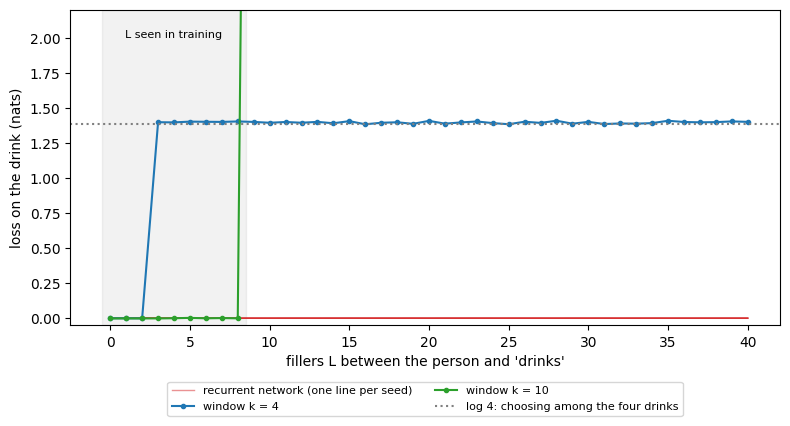

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, e in enumerate(rnn_eval):
    ax.plot(e.index, e["loss"], color="tab:red", alpha=0.5, linewidth=1, label="recurrent network (one line per seed)" if i == 0 else None)
for k, color in ((4, "tab:blue"), (10, "tab:green")):
    ax.plot(window_eval[k].index, window_eval[k]["loss"], color=color, marker="o", markersize=3, label=f"window k = {k}")
ax.axhline(np.log(4), color="gray", linestyle=":", label="log 4: choosing among the four drinks")
ax.axvspan(-0.5, 8.5, color="gray", alpha=0.1)
ax.text(4, 2.0, "L seen in training", ha="center", fontsize=8)
ax.set_ylim(-0.05, 2.2)                                      # the window k = 10 is far above this for L > 8 (see the table)
ax.set_xlabel("fillers L between the person and 'drinks'")
ax.set_ylabel("loss on the drink (nats)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
plt.tight_layout()

The two windows lose the person **abruptly** at their limit ($L = 3$ for $k = 4$, $L = 9$ for $k = 10$, which goes off the scale of the figure, to 10.5-12.5 nats as in the table above). The recurrent network is at zero over the whole range (the five lines overlap). A plausible reason is that the network uses at each step the same weights, so that what it learned in a few steps (*keep the person*) is applied for as many steps as needed; we have not tested other explanations. What the figure shows is that **reading one word at a time with a state removes the wall**, and it does so with a number of parameters that does not depend on $L$.

In [7]:
probability_table(12, {"window k = 4": window_predict[4], "window k = 10": window_predict[10], "RNN (seed 0)": rnn_predict[0], "RNN (seed 1)": rnn_predict[1]})

sara ... (12 fillers) ... drinks  ->  juice


,coffee,tea,milk,juice,loss of this sentence
window k = 4,0.23,0.26,0.25,0.26,1.36
window k = 10,1.00,0.00,0.00,0.00,9.81
RNN (seed 0),0.00,0.00,0.00,1.00,0.00
RNN (seed 1),0.00,0.00,0.00,1.00,0.00


On the same sentence the two recurrent networks give probability 1.00 to `juice`, the right drink, with a loss of 0.00: they have the information that the windows did not have.

## Step 3: but a recurrent network has problems of its own

The recurrent network passes the wall, but we have trained it in a favourable situation, and the way in which it does it has two costs.

### The words are read one after the other

In the backpropagation through time the step $t$ needs the state of the step $t - 1$, both in the forward and in the backward pass. The words of a sentence **can not be processed in parallel**: a sentence of $T$ words takes $T$ sequential steps, whatever the hardware. We measure it. For a batch of 64 sentences with $T$ fillers we time the forward pass of the recurrent network, which has a loop over the $T$ steps, and the **same network without the recurrence** (the term $W_h h_{t-1}$ removed, so that each position is computed from its own word only): the same operations, the same output layer and softmax, but all the positions at once, with no loop.

In [8]:
def milliseconds(f, repeat=30):
    f()
    t0 = time.perf_counter()
    for _ in range(repeat):
        f()
    return (time.perf_counter() - t0) / repeat * 1000

model = rnns[0]
rows = {}
for T in (20, 40, 80, 160):
    seq = sentences(np.random.default_rng(0), T, 64)
    loop = milliseconds(lambda: model.forward(seq))
    P = model.p
    parallel = milliseconds(lambda: softmax(np.tanh(P["E"][seq[:, :-1]] @ P["Wx"] + P["bh"]) @ P["Wy"] + P["by"]))    # no h_{t-1}: all the positions at once
    rows[T] = {"recurrent forward pass (ms)": loop, "same network without the recurrence (ms)": parallel,
               "recurrent time per step (ms)": loop / T, "recurrent / without recurrence": loop / parallel}
pd.DataFrame(rows).T.rename_axis("words T").style.format({"recurrent forward pass (ms)": "{:.2f}", "same network without the recurrence (ms)": "{:.2f}",
                                                         "recurrent time per step (ms)": "{:.3f}", "recurrent / without recurrence": "{:.1f}x"})

,recurrent forward pass (ms),same network without the recurrence (ms),recurrent time per step (ms),recurrent / without recurrence
words T,,,,
20,0.83,0.42,0.041,2.0x
40,1.51,0.85,0.038,1.8x
80,2.18,1.16,0.027,1.9x
160,4.14,2.24,0.026,1.8x


The recurrent forward pass is slower than the same network without the recurrence, **by a modest factor**: about 1.5 times for most of the lengths (the measure is noisy and changes from one run to another: in this run it goes from 1.2 to 2.7 times). It should not be overread: at this size the computation is tiny, the loop costs about 0.02 ms per step for the longer sequences, and a CPU has little to gain from parallelism with matrices of this size. The limit is structural: the recurrent network needs $T$ steps **in sequence**, while the other one needs one. On hardware that does thousands of operations in parallel (a GPU) the gap is larger, and it is the reason why the training of recurrent networks on long texts is slow; we have not measured it here.

### The signal of a distant word fades

The second problem is the one of the vanishing gradient. How much does the state $h_s$ affect a state $h_t$ that comes later? The answer is the product of the matrices of the steps in between:

$$
\frac{\partial h_t}{\partial h_s} = \prod_{j=s+1}^{t} \mathrm{diag}\left(1 - h_j^2\right) W_h
$$

and the same product multiplies the gradient when it goes back. Since $1 - h_j^2 \le 1$, the norm of the product is at most $\|W_h\|^{\,t-s}$, where $\|W_h\|$ is the largest singular value of $W_h$. If $\|W_h\| < 1$ the influence **decreases exponentially with the distance** $t - s$: the gradient that tells the network that the word $s$ was important for the word $t$ is exponentially small, and the network can not learn it. This is the **vanishing gradient**. If $\|W_h\| > 1$ the bound does not decrease and the product can grow exponentially (it is not certain, because the $\tanh$ saturates and the factor $1 - h_j^2$ becomes small): this is the exploding gradient, which the clipping handles. Both were described by Bengio, Simard and Frasconi (1994). In the toy example the influence we are interested in is exactly that of the person on the drink, $L + 1$ steps later.

We measure it: for a network that has not been trained, and for the same networks after the training, we compute the gradient of the loss of the drink with respect to each previous state, and we take the ratio between the norm at the state of the person and the norm at the state that predicts the drink. A ratio of $10^{-3}$ means that the signal that says that the person matters is a thousand times smaller than the one that says which drink to predict.

share of the units of the state with |h| > 0.99 while the fillers are read (L = 20): before the training 0.9%, after 80.8%


,before the training,after the training
fillers L,,
1,4.2e-01,1.9e-01
5,9.4e-02,6.6e-03
10,1.3e-02,3.7e-05
15,1.9e-03,9.8e-07
20,2.8e-04,2.5e-08
30,6.1e-06,1.9e-11
40,1.3e-07,2.0e-14


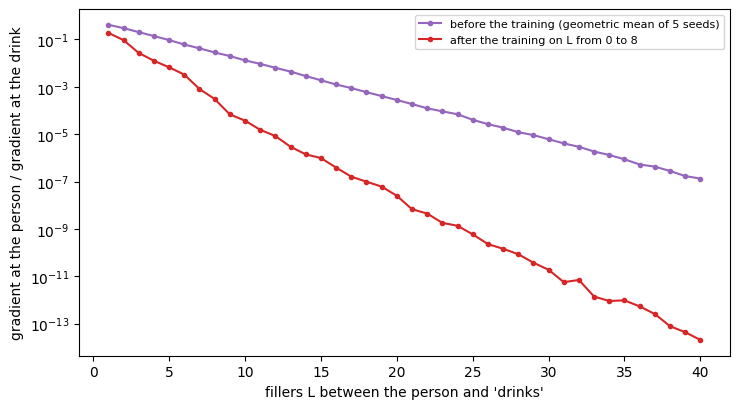

In [9]:
ratio_sentences = {L: sentences(np.random.default_rng(1000 + L), L, 100) for L in range(1, 41)}

def person_gradient_ratio(model, L):
    norms = model.state_gradient_norms(ratio_sentences[L], t_out=L + 2)
    return norms[L + 1] / norms[0]                               # the person is L + 1 steps before the state that predicts the drink

lengths = list(range(1, 41))
initial = np.array([[person_gradient_ratio(RNN(V, 8, 32, seed), L) for L in lengths] for seed in range(5)])
after = np.array([[person_gradient_ratio(m, L) for L in lengths] for m in rnns])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.semilogy(lengths, np.exp(np.log(initial).mean(axis=0)), color="tab:purple", marker="o", markersize=3, label="before the training (geometric mean of 5 seeds)")
ax.semilogy(lengths, np.exp(np.log(after).mean(axis=0)), color="tab:red", marker="o", markersize=3, label="after the training on L from 0 to 8")
ax.set_xlabel("fillers L between the person and 'drinks'")
ax.set_ylabel("gradient at the person / gradient at the drink")
ax.legend(fontsize=8)
plt.tight_layout()
def share_saturated(model, L=20):
    h, _ = model.forward(ratio_sentences[L])
    return (np.abs(h[:, 2:L + 2]) > 0.99).mean()                 # units of the state close to +1 or -1 while the fillers are read

print("share of the units of the state with |h| > 0.99 while the fillers are read (L = 20): "
      f"before the training {np.mean([share_saturated(RNN(V, 8, 32, seed)) for seed in range(5)]):.1%}, after {np.mean([share_saturated(m) for m in rnns]):.1%}")
pd.DataFrame({"before the training": np.exp(np.log(initial).mean(axis=0)), "after the training": np.exp(np.log(after).mean(axis=0))}, index=lengths).loc[[1, 5, 10, 15, 20, 30, 40]].rename_axis("fillers L").style.format("{:.1e}")

Before the training the ratio goes down **exponentially** with the distance: 0.42 for $L = 1$, 0.094 for $L = 5$, 0.013 for $L = 10$, $1.9 \times 10^{-3}$ for $L = 15$, $2.8 \times 10^{-4}$ for $L = 20$, $6.1 \times 10^{-6}$ for $L = 30$ and $1.3 \times 10^{-7}$ for $L = 40$. In the logarithmic scale it is a straight line, as the product of matrices of the theory predicts: from $L = 1$ to $L = 40$ it is divided by 3.2 million, a factor of about 0.68 per step (estimated from the two ends).

After the training the ratio is **much smaller, not larger**: $2.5 \times 10^{-8}$ at $L = 20$ and $2.0 \times 10^{-14}$ at $L = 40$, and yet these networks carry the person perfectly (loss 0.00). The two things are compatible. The ratio measures **how much signal the training has for learning that the person matters**, not how much the trained network remembers. After the training 80.8% of the units of the state are saturated ($|h| > 0.99$) while the fillers are read, against 0.9% before: the network keeps the person in units that do not change when a filler arrives, and in those units the factor $1 - h^2$ that multiplies the gradient at each step is close to zero (this agrees with the explanation, but we have not tested it in other ways). A stable memory has a tiny gradient, and this is why the training needs a place to start from. The next experiment removes it.

The networks of the first experiment had a help: the training sentences have all the lengths from 0 to 8, so that the network has seen the **short** dependencies, in which the person is right before the drink, and it could learn first to keep the person for one step and then for more. What if the only dependency to learn is a **long** one? We remove the help. We train the same network, with the same optimizer and the same clipping, on sentences that all have the **same** $L$: there is no short example from which to start. For each $L$ we train three networks with different initial weights, and we measure the loss on the drink at that same $L$ on new sentences. A network that learned the task has a loss near 0, one that did not stays near $\log 4 = 1.39$. We also record the time of the training, which grows with $L$ for the reason of the previous section.

In [10]:
rows = {}
for L in (5, 10, 20):
    t0 = time.time()
    group = {L: sentences(np.random.default_rng(7), L, 1000)}
    losses = sorted(drink_evaluation(rnn_probabilities(train_rnn(seed, group)), L)[0] for seed in range(3))
    rows[L] = {"loss of the three seeds, sorted": "  ".join(f"{v:.2f}" for v in losses),
               "seeds with loss < 0.5": f"{sum(v < 0.5 for v in losses)} of 3",
               "training time (3 networks)": f"{time.time() - t0:.0f} s"}
pd.DataFrame(rows).T.rename_axis("fillers L")

,"loss of the three seeds, sorted",seeds with loss < 0.5,training time (3 networks)
fillers L,,,
5,0.00 0.01 0.02,3 of 3,4 s
10,0.37 0.86 1.46,1 of 3,5 s
20,1.39 1.47 1.47,0 of 3,9 s


At $L = 5$ the three networks learn (losses 0.00, 0.01 and 0.02). At $L = 10$ only one of three learns (0.37, 0.86 and 1.46: the other two are partly there or worse than a random choice). At $L = 20$ **none of the three learns** (1.39, 1.47 and 1.47, the random choice or worse). Compare with the first experiment: the same network, with the same optimizer, the same clipping and the same number of steps, trained on $L$ from 0 to 8, carries the person up to $L = 40$ in all the five cases. **What makes the difference are the short examples**: they teach the network how to keep the person, and the same weights then keep it for longer. Alone, the long examples give a signal too weak to start from (the ratio of the gradients is of the order of $10^{-4}$ at $L = 20$, in the figure above). Adam, which rescales the step of each parameter, and the clipping, which cuts the large gradients, were used in both experiments, and neither repairs it, as we anticipated.

The limits: three networks for each $L$, 1,500 steps, one learning rate and one size of the network, so we do not know whether a longer training or other choices would succeed. The training time grows with $L$ (4, 5 and 8 seconds for three networks), for the reason of the previous section. In a real text there are dependencies at all the distances, but the long ones do not always have short ones that help to learn them.

## Step 4: LSTM and GRU

The vanishing gradient comes from the way in which the state is updated: at each step the old state is **rewritten**, through a matrix and a $\tanh$, and the gradient that crosses $L$ steps must cross $L$ rewrites. The idea of the **Long Short-Term Memory** (LSTM, Hochreiter and Schmidhuber, 1997) is to add to the state a second vector, the **cell** $c_t$, that is not rewritten but **updated by additions** under the control of **gates**: vectors of numbers between 0 and 1, computed from the input and from the previous state, that say how much of each component to keep, to write and to show. With $[h_{t-1}; e_{w_t}]$ the concatenation of the old state and of the embedding of the word, and $\sigma$ the sigmoid (which gives numbers between 0 and 1):

$$
f_t = \sigma\!\left(W_f [h_{t-1}; e_{w_t}] + b_f\right), \quad i_t = \sigma\!\left(W_i [h_{t-1}; e_{w_t}] + b_i\right), \quad o_t = \sigma\!\left(W_o [h_{t-1}; e_{w_t}] + b_o\right)
$$

$$
\tilde c_t = \tanh\!\left(W_c [h_{t-1}; e_{w_t}] + b_c\right), \qquad c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t, \qquad h_t = o_t \odot \tanh(c_t)
$$

The **forget gate** $f_t$ says how much of the old cell to keep, the **input gate** $i_t$ how much of the new candidate $\tilde c_t$ to write, and the **output gate** $o_t$ how much of the cell to show in the state $h_t$, which is what goes to the output layer. The important line is the one of $c_t$. Along the direct path the derivative of $c_t$ with respect to $c_{t-1}$ is $\mathrm{diag}(f_t)$, so that the gradient that crosses $L$ steps is multiplied by the product of $L$ forget gates, **numbers that the network can learn to keep near 1** for the components that must be remembered (and near 0 for those that must be forgotten), and not by a product of matrices whose norm tends to be below 1. In the toy example the network can learn to keep the person by setting to 1 the forget gate of the component that stores it, while it reads the fillers.

The **GRU** (Gated Recurrent Unit, Cho et al., 2014) is a simpler variant: no separate cell and two gates, the **update gate** $z_t$ and the **reset gate** $r_t$,

$$
z_t = \sigma\!\left(W_z [h_{t-1}; e_{w_t}] + b_z\right), \quad r_t = \sigma\!\left(W_r [h_{t-1}; e_{w_t}] + b_r\right), \quad \tilde h_t = \tanh\!\left(W_h [r_t \odot h_{t-1}; e_{w_t}] + b_h\right)
$$

$$
h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde h_t
$$

where $r_t$ decides how much of the old state to use for the candidate and $z_t$ how much of the state to replace. When $z_t$ is near 0 the state is **copied** unchanged, and the gradient passes through the same additive path of the LSTM. An LSTM has four blocks of weights ($W_f$, $W_i$, $W_o$, $W_c$), a GRU three ($W_z$, $W_r$, $W_h$) and the simple recurrent network that we wrote one: for a state of size $H$ and embeddings of size $d$ the number of parameters of the recurrent part is about $H(H + d)$ for the simple network, $3H(H + d)$ for the GRU and $4H(H + d)$ for the LSTM (plus the biases). In practice both are used in the same way as the simple network, and in PyTorch they are `nn.LSTM` and `nn.GRU`. We do not implement them: the notebook goes on with what they **do not** change.

**What the gates do not change.** (1) The state still depends on the previous one, so the words are still read **one after the other**, and the cost of the sequence is the same. (2) The whole history is still compressed in a **vector of fixed size**, and the more a sentence says, the more it has to forget. (3) The gates decide what to keep **while the words are being read**, using only the words read so far: the network does not know, when it reads a word, whether it will be needed.

## Step 5: the question comes at the end

In the toy dataset of the previous steps the word to remember was always the same, the person at the beginning of the sentence, and everything else was noise: a network can learn to keep the first word and to ignore the rest. We change the task so that **what is relevant depends on a question that arrives at the end**. Each sentence **lists $n$ people with a drink each**, and then asks about one of them:

`anna tea marco milk sara coffee . marco drinks` $\to$ `milk`

This time the drinks are random in each sentence (it is not a fixed fact, it is said in the sentence), so the answer must be **read from the list**. All the words of the list are potentially relevant, and the one that is relevant is known only at the end. A recurrent network has to decide what to keep **while it reads, before knowing the question**, so the whole list has to go through the state, a vector of fixed size. We train the recurrent network of the previous steps (the same code, 3,000 steps) on sentences with $n$ from 1 to 4, and we test it for each $n$. A random choice among the four drinks is right 25% of the time. A reference that knows **which drinks were listed but not who has which** chooses at random among the listed ones.

In [11]:
recall_words = ["<unk>", "<s>", "</s>", "drinks", "."] + people + drinks
recall_index = {w: i for i, w in enumerate(recall_words)}
RV = len(recall_words)
PERSON0, DRINK0 = recall_index["anna"], recall_index["coffee"]

def recall_sentences(rng, n, size):
    # <s> (person drink) x n . person drinks drink </s>: the sentence says who drinks what, then asks about one of the n people
    who = np.argsort(rng.random((size, len(people))), axis=1)[:, :n]          # n different people, in random order
    what = rng.integers(len(drinks), size=(size, n))                           # a random drink for each of them
    asked = rng.integers(n, size=size)
    out = np.empty((size, 2 * n + 6), dtype=np.int64)
    out[:, 0] = START
    out[:, 1:2 * n + 1:2] = PERSON0 + who
    out[:, 2:2 * n + 2:2] = DRINK0 + what
    out[:, 2 * n + 1] = recall_index["."]
    out[:, 2 * n + 2] = PERSON0 + who[np.arange(size), asked]
    out[:, 2 * n + 3] = recall_index["drinks"]
    out[:, 2 * n + 4] = DRINK0 + what[np.arange(size), asked]
    out[:, 2 * n + 5] = END
    return out, asked

recall_show = lambda s: " ".join(recall_words[i] for i in s[1:-1])
rng = np.random.default_rng(3)
for n in (1, 2, 4):
    print(f"n = {n}:", recall_show(recall_sentences(rng, n, 1)[0][0]))

rng = np.random.default_rng(0)
recall_train = {n: recall_sentences(rng, n, 4000)[0] for n in (1, 2, 3, 4)}
recall_test = {n: recall_sentences(np.random.default_rng(99 + n), n, 400) for n in (1, 2, 3, 4)}

t0 = time.time()
recall_rnns = [train_rnn(seed, recall_train, steps=3000, vocabulary_size=RV) for seed in range(3)]
print(f"three networks trained in {time.time() - t0:.0f} s")
recall_predict = [rnn_probabilities(m) for m in recall_rnns]

def recall_accuracy(predict, n):
    seq, _ = recall_test[n]
    return (predict(seq[:, :2 * n + 4]).argmax(axis=1) == seq[:, 2 * n + 4]).mean()

listed_reference = lambda n: np.mean([1 / len(set(row[2:2 * n + 1:2])) for row in recall_test[n][0]])
accuracy_table = pd.DataFrame({**{f"RNN seed {i}": {n: recall_accuracy(p, n) for n in recall_test} for i, p in enumerate(recall_predict)},
                               "choose among the listed drinks": {n: listed_reference(n) for n in recall_test}}).rename_axis("people listed n")
accuracy_table.style.format("{:.0%}")

n = 1: anna coffee . anna drinks coffee
n = 2: luca coffee anna coffee . luca drinks coffee
n = 4: anna coffee luca milk marco juice sara juice . sara drinks juice


three networks trained in 8 s


,RNN seed 0,RNN seed 1,RNN seed 2,choose among the listed drinks
people listed n,,,,
1,100%,100%,100%,100%
2,64%,62%,71%,62%
3,42%,50%,57%,47%
4,38%,36%,42%,38%


With one person in the list the network is right every time (100% for the three seeds): it keeps the only drink that it has read. With more people the accuracy falls: 64%, 62% and 71% for $n = 2$, 42%, 50% and 57% for $n = 3$, 38%, 36% and 42% for $n = 4$ (the random choice is 25%). And it is **about the same as the reference that knows only which drinks were listed**: 62%, 47% and 38%. The network keeps part of the list, but not who has which. A limit: the networks are small (32 units) and trained for 3,000 steps, and we do not know how far a bigger state or a longer training would go. What matters here is that the accuracy falls when the list grows.

Where does the prediction come from? We use the same question as before: we **replace one word and we measure how much the prediction changes**. Now the words that we replace are the drinks of the list (each of them, one at a time, with each of the three other drinks), and the change is measured as the **total variation distance** between the two distributions of the answer, $\frac{1}{2}\sum_w |p(w) - p'(w)|$: 0 if the answer does not change, 1 if it becomes completely different. A network that has really selected the relevant word depends on **the drink of the asked person and on no other**: the influence of the drink of the asked person is near 1 and that of the others near 0.

In [12]:
total_variation = lambda p, q: 0.5 * np.abs(p - q).sum(axis=-1)

def listed_drink_influence(predict, seq, n):
    # for each of the n drinks of the list: mean over the 3 other drinks of the distance between the answer and the answer
    # obtained when that drink is replaced
    prefix = seq[:, :2 * n + 4]
    base = predict(prefix)
    out = np.zeros((len(seq), n))
    for j in range(n):
        changes = []
        for drink in range(len(drinks)):
            alternative = prefix.copy()
            different = alternative[:, 2 + 2 * j] != DRINK0 + drink
            alternative[:, 2 + 2 * j] = DRINK0 + drink
            changes.append(np.where(different, total_variation(base, predict(alternative)), np.nan))
        out[:, j] = np.nanmean(changes, axis=0)
    return out

rows = {}
for n in (2, 3, 4):
    seq, asked = recall_test[n]
    others = np.ones((len(seq), n), dtype=bool)
    others[np.arange(len(seq)), asked] = False
    for seed, predict in enumerate(recall_predict):
        influence = listed_drink_influence(predict, seq, n)
        rows[n, f"seed {seed}"] = {"accuracy": recall_accuracy(predict, n),
                                   "influence of the drink of the asked person": influence[~others].mean(),
                                   "influence of the other listed drinks": influence[others].mean()}
pd.DataFrame(rows).T.rename_axis(["people listed n", "network"]).style.format("{:.2f}", subset=["influence of the drink of the asked person", "influence of the other listed drinks"]).format("{:.0%}", subset=["accuracy"])

The influence of the drink of the asked person is only a little larger than that of the other drinks of the list: 0.39 against 0.31, 0.50 against 0.41 and 0.57 against 0.43 for $n = 2$ (the three seeds), 0.20 against 0.15, 0.33 against 0.25 and 0.37 against 0.30 for $n = 3$, 0.16 against 0.10, 0.21 against 0.16 and 0.25 against 0.22 for $n = 4$. A network that selected the relevant word would be near 1 for the drink of the asked person and near 0 for the others. Here the prediction **depends on all the drinks of the list**, almost as much as on the right one: the network does not discriminate which word is relevant, and it could not do it while reading, because the question had not arrived.

The problem is not that the network does not know which word to keep: it is that **it can not know it while it reads**, because the question has not arrived, and so it keeps what it can of the whole list in a vector of fixed size. This comes from reading in order with a state, and we expect that the gates of an LSTM or of a GRU do not change it, because they also decide what to keep before the question is known (we have not tested it). What would help is a way for the question, when it arrives, to **go back to the list and take what it needs**. We come back to this at the end.

## Step 6: making the order explicit, the positional embeddings

We have seen three ways of handling the order of the words in a text, and we add a fourth.

| model | where is the order | length of the text |
|---|---|---|
| bag of words (sum or mean of the embeddings) | nowhere: it is lost | any |
| window network (concatenation) | in the **slot**: each position of the window has its own weights | fixed, $k$ words |
| recurrent network (RNN, LSTM, GRU) | in the **process**: the state depends on the order in which the words are read | any |
| positional embeddings | in the **input**: the vector of each word contains its position | any (up to a maximum if they are learned) |

In the recurrent network the order is **delegated to the process**: the network does not know where a word is, it only knows what it has read before. The alternative is to make the order **explicit** and to put it into the embedding: the vector of the word at position $t$ is the embedding of the word **plus a vector that depends on the position**,

$$
x_t = e_{w_t} + p_t
$$

Two texts with the same words in a different order now have different vectors, and nothing has to be read in sequence: the vectors of all the positions can be computed **at the same time**, and this removes the first problem of Step 3.

### Which vectors for the positions?

There are two choices. The vectors $p_t$ can be a table **learned** like the table of the embeddings, one row for each position up to a maximum length. Or they can be **fixed**, and the classical choice is the sinusoidal one of Vaswani et al. (2017), for a vector of size $d$:

$$
p_{t,2i} = \sin\left(\frac{t}{10000^{2i/d}}\right), \qquad p_{t,2i+1} = \cos\left(\frac{t}{10000^{2i/d}}\right)
$$

Each pair of components is a sinusoid of a different wavelength, from fast ones to very slow ones, so that every position has its own pattern, and it exists for any $t$. Another property is that the dot product of two positions depends **only on how far they are**: $p_t \cdot p_{t'} = \sum_i \cos\left((t - t')\,\omega_i\right)$, with $\omega_i = 10000^{-2i/d}$, and not on where they are. We check it.

largest difference between the curves of the three starting positions: 7.1e-15


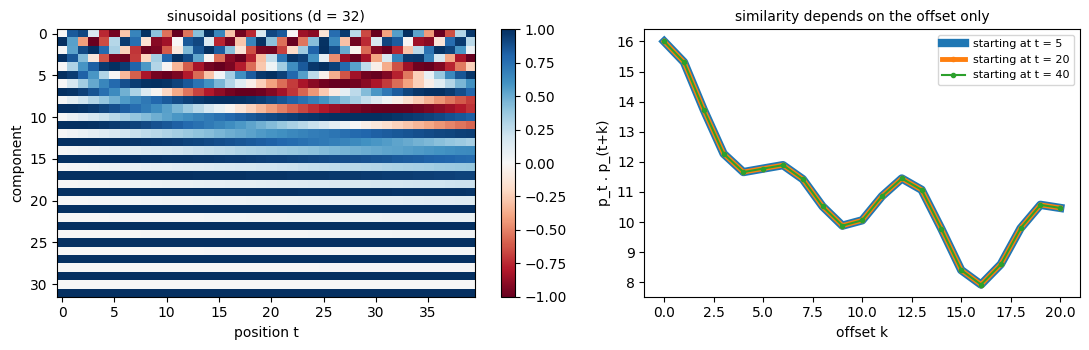

In [13]:
def sinusoid(T, d):
    t = np.arange(T)[:, None]
    omega = 1 / 10000 ** (np.arange(0, d, 2) / d)
    pe = np.zeros((T, d))
    pe[:, 0::2] = np.sin(t * omega)
    pe[:, 1::2] = np.cos(t * omega)
    return pe

PE = sinusoid(64, 32)
similarity = PE @ PE.T                                                   # p_t . p_t'
offsets = np.arange(0, 21)
curves = {t: [similarity[t, t + k] for k in offsets] for t in (5, 20, 40)}
print("largest difference between the curves of the three starting positions:",
      f"{max(abs(np.array(curves[a]) - np.array(curves[b])).max() for a in curves for b in curves):.1e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.2, 1]})
im = axes[0].imshow(PE[:40].T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
axes[0].set_xlabel("position t")
axes[0].set_ylabel("component")
axes[0].set_title("sinusoidal positions (d = 32)", fontsize=10)
plt.colorbar(im, ax=axes[0])
for (t, c), width in zip(curves.items(), (6, 3.5, 1.5)):                      # different widths, to see that the curves overlap
    axes[1].plot(offsets, c, marker="o", markersize=3, linewidth=width, label=f"starting at t = {t}")
axes[1].set_xlabel("offset k")
axes[1].set_ylabel("p_t . p_(t+k)")
axes[1].set_title("similarity depends on the offset only", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()

The similarity of a position with itself is 16, that is $d/2$, and it decreases with the offset (not monotonically, because there are many frequencies). The curves for the three starting positions, $t$ = 5, 20 and 40, **coincide** (they are drawn with different widths to show that they overlap): the largest difference between them is $7.1 \times 10^{-15}$. The similarity between two positions depends on how far they are and not on where they are, a property that a table of learned vectors can learn but does not have by construction.

### What the positions give, and what they do not

We take two sentences of the list with the same words in a different order, `anna tea marco milk` and `anna milk marco tea`, and we look at four ways of turning the vectors of their words into **one** vector: the sum of the embeddings (the bag), the sum after a layer with ReLU applied to each vector, and the same two with the position added to each vector. The embeddings and the weights of the layer are random: the question is about the construction, not about training. We print the distance between the vectors of the two sentences.

In [14]:
rng = np.random.default_rng(0)
E_demo = rng.normal(size=(RV, 32))
W_demo = rng.normal(size=(32, 128)) / np.sqrt(32)
to_ids = lambda text: np.array([recall_index[w] for w in text.split()])
a, b = to_ids("anna tea marco milk"), to_ids("anna milk marco tea")           # the same words in a different order

def pooled(tokens, positions, relu):
    x = E_demo[tokens] + (PE[1:len(tokens) + 1] if positions else 0)
    return (np.maximum(x @ W_demo, 0) if relu else x).sum(axis=0)

pd.DataFrame({"distance between the two sentences": {
    "sum of the embeddings (bag)": np.linalg.norm(pooled(a, False, False) - pooled(b, False, False)),
    "sum after a ReLU layer": np.linalg.norm(pooled(a, False, True) - pooled(b, False, True)),
    "sum of embedding + position": np.linalg.norm(pooled(a, True, False) - pooled(b, True, False)),
    "sum of ReLU(embedding + position)": np.linalg.norm(pooled(a, True, True) - pooled(b, True, True))}}).style.format("{:.2e}")

,distance between the two sentences
sum of the embeddings (bag),1.51e-15
sum after a ReLU layer,1.78e-15
sum of embedding + position,1.66e-15
sum of ReLU(embedding + position),2.74e+00


The distance between the two sentences is zero (about $10^{-15}$, the rounding error of the computer) for the bag, for the sum after a ReLU layer **and for the sum of embedding plus position**: the positions that are added and then summed give back the bag, as the formula says. Only the last way, a ReLU applied to embedding plus position **before** the sum, tells the two sentences apart (distance 2.74). The sum after a ReLU layer **without** positions does not do it either: the two sentences have the same set of vectors, and so the same sum.

The sum of embedding plus position is as blind to the order as the bag. The reason is simple: the sum is linear, so $\sum_t (e_{w_t} + p_t) = \sum_t e_{w_t} + \sum_t p_t$, which is the bag of words plus a vector that depends only on the length of the text. The information on the order is **in each vector, and the sum erases it**. It survives if each vector goes through a nonlinear function **before** the sum, so that the word and the position are mixed in a way that can not be separated. We test it on the question at the end. We train three small networks that turn each position into a vector, add the vectors and compute the answer with an MLP, with two different initializations each: *(B)* the sum of embedding plus position, *(C)* the sum after a ReLU layer, without positions, *(D)* the sum after a ReLU layer, with positions. In all of them there is no recurrence, no loop and no order in which the words are read.

In [15]:
class Pooled(torch.nn.Module):
    # x_t = e(w_t) (+ p_t); optionally h_t = ReLU(W x_t); the vectors of all the positions are added and an MLP gives the scores
    def __init__(self, positions, nonlinear, d=32, hidden=128, max_length=20):
        super().__init__()
        self.E = torch.nn.Embedding(RV, d)
        self.positions = positions
        self.register_buffer("PE", torch.tensor(sinusoid(max_length, d), dtype=torch.float32))
        self.per_position = torch.nn.Sequential(torch.nn.Linear(d, hidden), torch.nn.ReLU()) if nonlinear else torch.nn.Identity()
        self.mlp = torch.nn.Sequential(torch.nn.Linear(hidden if nonlinear else d, hidden), torch.nn.ReLU(), torch.nn.Linear(hidden, RV))

    def vectors(self, prefix):                                            # one vector for each position
        x = self.E(prefix)
        if self.positions:
            x = x + self.PE[:prefix.shape[1]]
        return self.per_position(x)

    def forward(self, prefix):
        return self.mlp(self.vectors(prefix).sum(dim=1))

def train_pooled(positions, nonlinear, seed, steps=6000, lr=3e-3, batch=128):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = Pooled(positions, nonlinear)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        n = int(rng.integers(1, 5))
        sentences_n = torch.as_tensor(recall_train[n][rng.integers(len(recall_train[n]), size=batch)])
        loss = F.cross_entropy(model(sentences_n[:, :2 * n + 4]), sentences_n[:, 2 * n + 4])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model

def pooled_accuracy(model, n):
    seq, _ = recall_test[n]
    with torch.no_grad():
        return (model(torch.as_tensor(seq[:, :2 * n + 4])).argmax(dim=-1).numpy() == seq[:, 2 * n + 4]).mean()

t0 = time.time()
variants = {"B: sum of embedding + position": (True, False), "C: sum of ReLU(embedding), no positions": (False, True),
            "D: sum of ReLU(embedding + position)": (True, True)}
pooled_models = {name: [train_pooled(positions, nonlinear, seed) for seed in range(2)] for name, (positions, nonlinear) in variants.items()}
print(f"six networks trained in {time.time() - t0:.0f} s")
comparison = pd.DataFrame({**{name: {n: np.mean([pooled_accuracy(m, n) for m in models]) for n in recall_test} for name, models in pooled_models.items()},
                           "RNN of Step 5 (mean of 3 seeds)": {n: accuracy_table.loc[n, [f"RNN seed {i}" for i in range(3)]].mean() for n in recall_test},
                           "choose among the listed drinks": accuracy_table["choose among the listed drinks"]}).rename_axis("people listed n")
comparison.style.format("{:.0%}")

six networks trained in 24 s


,B: sum of embedding + position,"C: sum of ReLU(embedding), no positions",D: sum of ReLU(embedding + position),RNN of Step 5 (mean of 3 seeds),choose among the listed drinks
people listed n,,,,,
1,100%,100%,100%,100%,100%
2,62%,64%,100%,66%,62%
3,60%,59%,89%,50%,47%
4,49%,49%,70%,39%,38%


The networks B and C, which can not tell the order, are at the level of the reference that knows only the listed drinks: 62% and 64% for $n = 2$, 60% and 59% for $n = 3$, 49% and 49% for $n = 4$ (the reference is 62%, 47% and 38%). The network D, with a nonlinear layer on embedding plus position, reaches **100%, 89% and 70%** (mean of two seeds): the information on the order is used. The comparison with the recurrent network (66%, 50% and 39%) is not controlled: the budgets are different (3,000 steps against 6,000, with different learning rates), and we have not searched for the best settings of any of the models. What the table says is that the explicit position is useful when the model has a way to mix it with the word before the sum, and that even so the accuracy falls with the length of the list (70% for $n = 4$, from 100% for $n = 2$). A plausible reason is that this MLP has to recover all the pairings, in one step, from a sum of vectors; we have not tested it.

### The positions do not talk to each other

Even when it is used well, the position is a property of **each vector on its own**. We make it concrete with one more measure: in a sentence with three people we replace the first drink of the list (position 2) with another drink, and we look at **how much the vector of each position changes**, for the recurrent network of Step 5 (its state) and for the network D that has the positional embeddings (the vector that it computes for each position before the sum).

In [16]:
n = 3
seq, _ = recall_test[n]
prefix = seq[:, :2 * n + 4]
position = 2                                                              # the first drink of the list
network_D = pooled_models["D: sum of ReLU(embedding + position)"][0]
rnn_model = recall_rnns[0]

def state_change(replacement):
    alternative = prefix.copy()
    alternative[:, position] = DRINK0 + replacement
    keep = prefix[:, position] != DRINK0 + replacement
    h, _ = rnn_model.forward(np.concatenate([prefix, np.zeros((len(prefix), 1), dtype=np.int64)], axis=1))
    h2, _ = rnn_model.forward(np.concatenate([alternative, np.zeros((len(prefix), 1), dtype=np.int64)], axis=1))
    with torch.no_grad():
        v = network_D.vectors(torch.as_tensor(prefix)).numpy()
        v2 = network_D.vectors(torch.as_tensor(alternative)).numpy()
    return (np.array([np.linalg.norm(h2[keep, t + 1] - h[keep, t + 1], axis=1).mean() for t in range(prefix.shape[1])]),
            np.array([np.linalg.norm(v2[keep, t] - v[keep, t], axis=1).mean() for t in range(prefix.shape[1])]))

changes = [state_change(r) for r in range(len(drinks))]
pd.DataFrame({"recurrent network (state)": np.mean([c[0] for c in changes], axis=0),
              "network D (vector of the position)": np.mean([c[1] for c in changes], axis=0)},
             index=pd.Index([recall_words[i] for i in recall_test[n][0][0, :2 * n + 4]], name="position t (word of the first sentence)")).style.format("{:.2f}").format_index(escape="html")

,recurrent network (state),network D (vector of the position)
position t (word of the first sentence),,
<s>,0.00,0.00
anna,0.00,0.00
coffee,3.96,8.75
sara,2.97,0.00
milk,2.51,0.00
marco,1.64,0.00
tea,1.38,0.00
.,1.10,0.00
sara,1.25,0.00


In the recurrent network the change of the first drink **travels along the sequence**: the state changes by 3.96 at the position of the word, and it keeps changing at all the following positions (2.97, 2.51, 1.64, 1.38, 1.10, 1.25 and 1.16), because each state is computed from the previous one (the positions before it do not change, since the network reads from left to right). In the network D the vector changes by 8.75 at the position of the word and by **exactly 0 at all the others**: the positions do not talk. The sizes of the two columns can not be compared (the states of the recurrent network are between $-1$ and 1, the vectors of D are not bounded): what we compare is the pattern.

## What is still open

The positional embeddings make the order **explicit**: it is no longer the result of a process that reads the words one after the other, it is a part of the vector of each word. The consequences are two. The vectors of all the positions can be computed **at the same time**, with no loop, and so the first problem of the recurrent networks, the slowness, is gone. And the order is **available to any operation** that comes after, even one that does not read in sequence.

But the table above shows what the positions do not do. The vector of a position knows its word and its place, and **nothing about the other positions**: the order is available, but nothing connects the words. The network D uses it with an MLP after a sum, which is a way to make everything meet in one place, and the accuracy of the table above says how far this goes. What we need is a mechanism with which **each position can look at the others and choose which ones matter**, as a function of the content: the question at the end of Step 5 should be able to go back to the list and take the drink of the right person. This is the **attention**, and it is the subject of the next notebook, where positional embeddings and attention together give the Transformer.